<a href="https://colab.research.google.com/github/simplyshree/Skin---Les-Analyzer/blob/main/skin_lesion_analyzerfinal_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Skin Lesion Analyzer — Complete Colab Workflow

This notebook runs the image-only project end to end:

1. Upload the project ZIP.
2. Download and verify ISIC 2018 Task 1 image/mask pairs.
3. Train the compact U-Net.
4. Evaluate Otsu, K-means + morphology, and U-Net on the same held-out test set.
5. Save real Dice/IoU results.
6. Create a visual comparison figure.
7. Extract the descriptive ABCD-style image features.
8. Download the trained model and presentation outputs.

The output is an educational image-analysis result. It is not a medical diagnosis or clinical decision tool.

## Before starting
Create a ZIP of the local `skin-lesion-analyzer` project folder. The ZIP should contain `analyzer/`, `model/`, `results/`, and `notebooks/`. Upload that ZIP when the notebook asks for it.

In [1]:
%pip install -q opencv-python-headless pandas scikit-learn Pillow matplotlib tensorflow
print('Dependencies installed.')

Dependencies installed.


In [2]:
from pathlib import Path
import shutil
import sys
import zipfile

from google.colab import files

PROJECT_ROOT = Path('/content/skin-lesion-analyzer')

if not (PROJECT_ROOT / 'analyzer' / 'data_loader.py').exists():
    print('Upload the ZIP of the skin-lesion-analyzer project.')
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if not zip_names:
        raise FileNotFoundError('Please upload a .zip file containing the skin-lesion-analyzer project.')
    upload_name = zip_names[0]
    extract_root = Path('/content/project_upload')
    if extract_root.exists():
        shutil.rmtree(extract_root)
    extract_root.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(upload_name) as archive:
        archive.extractall(extract_root)
    candidates = list(extract_root.rglob('analyzer/data_loader.py'))
    if not candidates:
        raise FileNotFoundError('The ZIP must contain an analyzer/data_loader.py file.')
    detected_root = candidates[0].parent.parent
    if PROJECT_ROOT.exists():
        shutil.rmtree(PROJECT_ROOT)
    shutil.copytree(detected_root, PROJECT_ROOT)

print('Using project:', PROJECT_ROOT)
assert (PROJECT_ROOT / 'analyzer' / 'data_loader.py').exists()

Upload the ZIP of the skin-lesion-analyzer project.


Saving skin-lesion-analyzer.zip to skin-lesion-analyzer.zip
Using project: /content/skin-lesion-analyzer


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import tensorflow as tf

from sklearn.model_selection import train_test_split

sys.path.insert(0, str(PROJECT_ROOT))

from analyzer.data_loader import download_isic2018, pair_image_masks
from analyzer.preprocessing import resize_image
from analyzer.classical_segmentation import otsu_segmentation, kmeans_segmentation
from analyzer.metrics import dice_score, iou_score, summarize_scores
from analyzer.unet_segmentation import build_unet, compile_unet, predict_unet
from analyzer.abcd_features import extract_abcd_features

SEED = 42
NUM_SAMPLES = 500  # Use 20 for a quick test; use 500 or None for a stronger run.
TARGET_SIZE = (256, 256)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('Project:', PROJECT_ROOT)

TensorFlow: 2.21.0
Project: /content/skin-lesion-analyzer


## Download and verify the ISIC 2018 dataset

This uses the official ISIC 2018 Task 1 archive URLs through the project loader. No Kaggle API token is required. The archives may be large and can take several minutes to download.

In [6]:
import shutil
import zipfile
from pathlib import Path

import requests
from analyzer.data_loader import pair_image_masks

DATA_CACHE = Path("/content/isic2018_cache")

# Remove the corrupted/incomplete download
if DATA_CACHE.exists():
    shutil.rmtree(DATA_CACHE)
DATA_CACHE.mkdir(parents=True, exist_ok=True)

URLS = {
    "training_images.zip":
        "https://isic-archive.s3.amazonaws.com/challenges/2018/ISIC2018_Task1-2_Training_Input.zip",

    "training_masks.zip":
        "https://isic-archive.s3.amazonaws.com/challenges/2018/ISIC2018_Task1_Training_GroundTruth.zip",
}

def download_and_extract(url, archive_name):
    archive_path = DATA_CACHE / archive_name
    extract_path = DATA_CACHE / archive_path.stem

    print("Downloading:", archive_name)

    response = requests.get(
        url,
        stream=True,
        timeout=180,
        headers={"User-Agent": "Mozilla/5.0"},
    )
    response.raise_for_status()

    with open(archive_path, "wb") as output:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                output.write(chunk)

    if not zipfile.is_zipfile(archive_path):
        first_bytes = archive_path.read_bytes()[:200]
        raise RuntimeError(
            f"Downloaded file is not a valid ZIP. First bytes: {first_bytes!r}"
        )

    if not extract_path.exists():
        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(extract_path)

    return extract_path

image_root = download_and_extract(
    URLS["training_images.zip"],
    "training_images.zip",
)

mask_root = download_and_extract(
    URLS["training_masks.zip"],
    "training_masks.zip",
)

all_pairs = pair_image_masks(image_root, mask_root)

if NUM_SAMPLES is None:
    pairs = all_pairs
else:
    pairs = all_pairs[:NUM_SAMPLES]

print("Verified image/mask pairs:", len(all_pairs))
print("Pairs used:", len(pairs))

Downloading: training_images.zip
Downloading: training_masks.zip
Verified image/mask pairs: 2594
Pairs used: 500


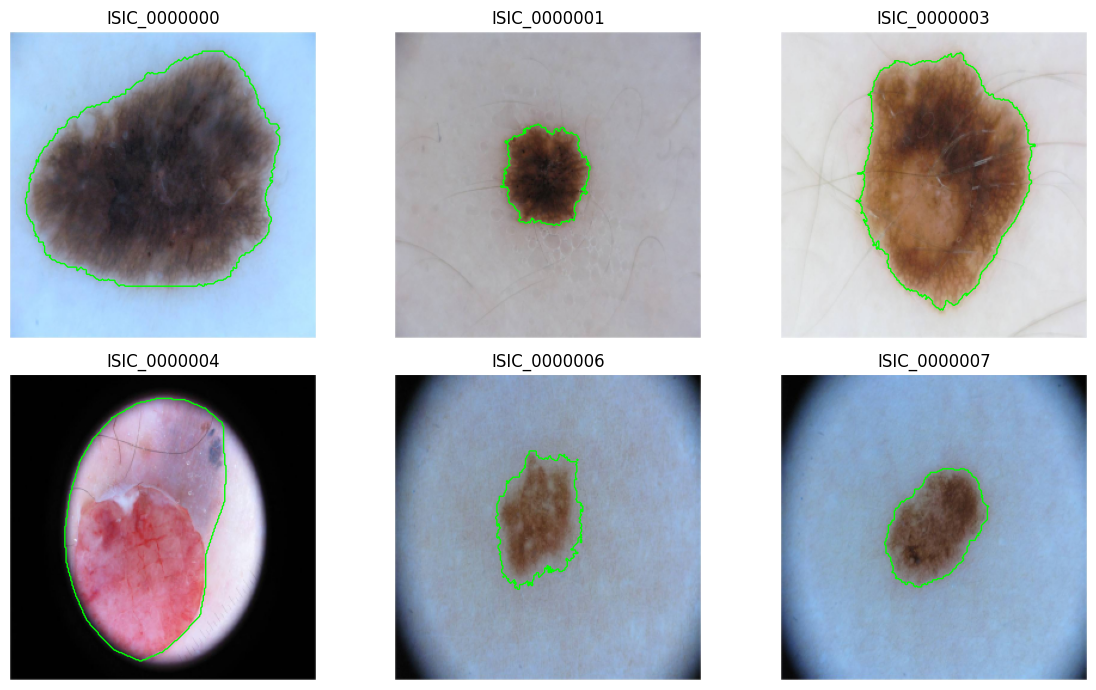

In [7]:
def load_pair(pair):
    image = np.asarray(Image.open(pair[0]).convert('RGB'))
    mask = np.asarray(Image.open(pair[1]).convert('L'))
    image = resize_image(image, TARGET_SIZE)
    mask = cv2.resize(mask, (TARGET_SIZE[1], TARGET_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    return image, (mask > 0).astype(np.uint8)

preview_count = min(6, len(pairs))
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, pair in zip(axes.flat, pairs[:preview_count]):
    image, mask = load_pair(pair)
    ax.imshow(image)
    ax.contour(mask, levels=[0.5], colors='lime', linewidths=1)
    ax.set_title(pair[0].stem)
    ax.axis('off')
for ax in axes.flat[preview_count:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:
loaded = [load_pair(pair) for pair in pairs]
images_uint8 = np.stack([image for image, _ in loaded])
masks_uint8 = np.stack([mask for _, mask in loaded])
images = images_uint8.astype('float32') / 255.0
masks = masks_uint8.astype('float32')[..., None]

indices = np.arange(len(images))
train_idx, test_idx = train_test_split(indices, test_size=0.20, random_state=SEED)
train_idx, val_idx = train_test_split(train_idx, test_size=0.20, random_state=SEED)

print({'train': len(train_idx), 'validation': len(val_idx), 'test': len(test_idx)})
assert len(test_idx) >= 2

{'train': 320, 'validation': 80, 'test': 100}


## Train the compact U-Net

The best checkpoint is selected using validation loss. The final U-Net score is calculated only on the held-out test set.

In [9]:
MODEL_DIR = PROJECT_ROOT / 'model'
RESULTS_DIR = PROJECT_ROOT / 'results'
FIGURES_DIR = RESULTS_DIR / 'figures'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / 'unet_skin_lesion.keras'
model = compile_unet(build_unet((*TARGET_SIZE, 3)))
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2),
    tf.keras.callbacks.ModelCheckpoint(model_path, save_best_only=True),
]

history = model.fit(
    images[train_idx],
    masks[train_idx],
    validation_data=(images[val_idx], masks[val_idx]),
    epochs=25,
    batch_size=4,
    callbacks=callbacks,
)

print('Saved model:', model_path)
assert model_path.exists()

Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 52s 206ms/step - dice_metric: 0.6658 - iou: 0.6458 - loss: 0.6996 - val_dice_metric: 0.2770 - val_iou: 0.0000e+00 - val_loss: 1.3365 - learning_rate: 1.0000e-04
Epoch 2/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 140ms/step - dice_metric: 0.7444 - iou: 0.7371 - loss: 0.5164 - val_dice_metric: 0.1713 - val_iou: 0.0000e+00 - val_loss: 1.5359 - learning_rate: 1.0000e-04
Epoch 3/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 142ms/step - dice_metric: 0.7774 - iou: 0.7716 - loss: 0.4471 - val_dice_metric: 0.0957 - val_iou: 0.0000e+00 - val_loss: 1.7972 - learning_rate: 1.0000e-04
Epoch 4/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 145ms/step - dice_metric: 0.8058 - iou: 0.8045 - loss: 0.3826 - val_dice_metric: 0.0600 - val_iou: 0.0000e+00 - val_loss: 1.9973 - learning_rate: 1.0000e-05
Epoch 5/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 148ms/step - dice_metric: 0.8155 - iou: 0.8213 - loss: 0.3560 - val_dice_metric: 0.0827 - val_iou: 0.0030 - val_loss: 1.9385 - learning_rate: 1.0000e-05
Epoch 6/2

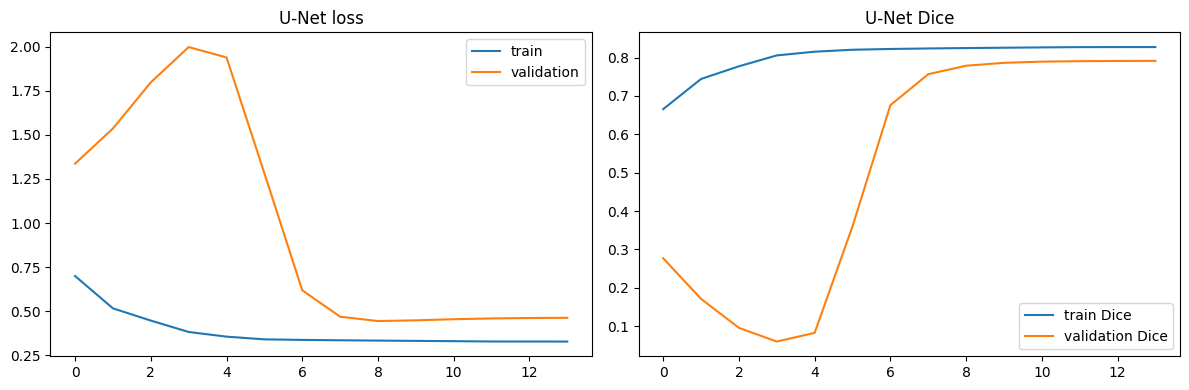

In [10]:
history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df['loss'], label='train')
axes[0].plot(history_df['val_loss'], label='validation')
axes[0].set_title('U-Net loss')
axes[0].legend()
axes[1].plot(history_df['dice_metric'], label='train Dice')
axes[1].plot(history_df['val_dice_metric'], label='validation Dice')
axes[1].set_title('U-Net Dice')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## Evaluate all three methods on the same held-out test set

This is the final comparison used in the presentation. Otsu, K-means, and U-Net all use exactly the same `test_idx` images and expert masks.

In [11]:
def evaluate_method(method):
    ious, dices = [], []
    for idx in test_idx:
        image = images_uint8[idx]
        truth = masks_uint8[idx]
        if method == 'Otsu':
            prediction = otsu_segmentation(image)
        elif method == 'K-means + Morphology':
            prediction = kmeans_segmentation(image)
        elif method == 'U-Net':
            prediction = predict_unet(model, image)
        else:
            raise ValueError(method)
        ious.append(iou_score(prediction, truth))
        dices.append(dice_score(prediction, truth))
    return summarize_scores(ious, dices)

results = pd.DataFrame([
    {'dataset': 'ISIC2018_Task1', 'source': 'executed Colab benchmark on held-out test split', 'method': method, **evaluate_method(method)}
    for method in ['Otsu', 'K-means + Morphology', 'U-Net']
])
results = results.sort_values(['mean_dice', 'mean_iou'], ascending=False).reset_index(drop=True)
results.to_csv(RESULTS_DIR / 'benchmark_results.csv', index=False)

display(results)
print('Selected method:', results.iloc[0]['method'])
print('Saved:', RESULTS_DIR / 'benchmark_results.csv')

,dataset,source,method,n_samples,mean_iou,std_iou,median_iou,mean_dice,std_dice,median_dice
0,ISIC2018_Task1,executed Colab benchmark on held-out test split,U-Net,100,0.757573,0.198944,0.815040,0.843036,0.171547,0.898095
1,ISIC2018_Task1,executed Colab benchmark on held-out test split,Otsu,100,0.607619,0.273324,0.662621,0.710754,0.269990,0.797076
2,ISIC2018_Task1,executed Colab benchmark on held-out test split,K-means + Morphology,100,0.561836,0.294455,0.636821,0.663121,0.303717,0.778119


Selected method: U-Net
Saved: /content/skin-lesion-analyzer/results/benchmark_results.csv


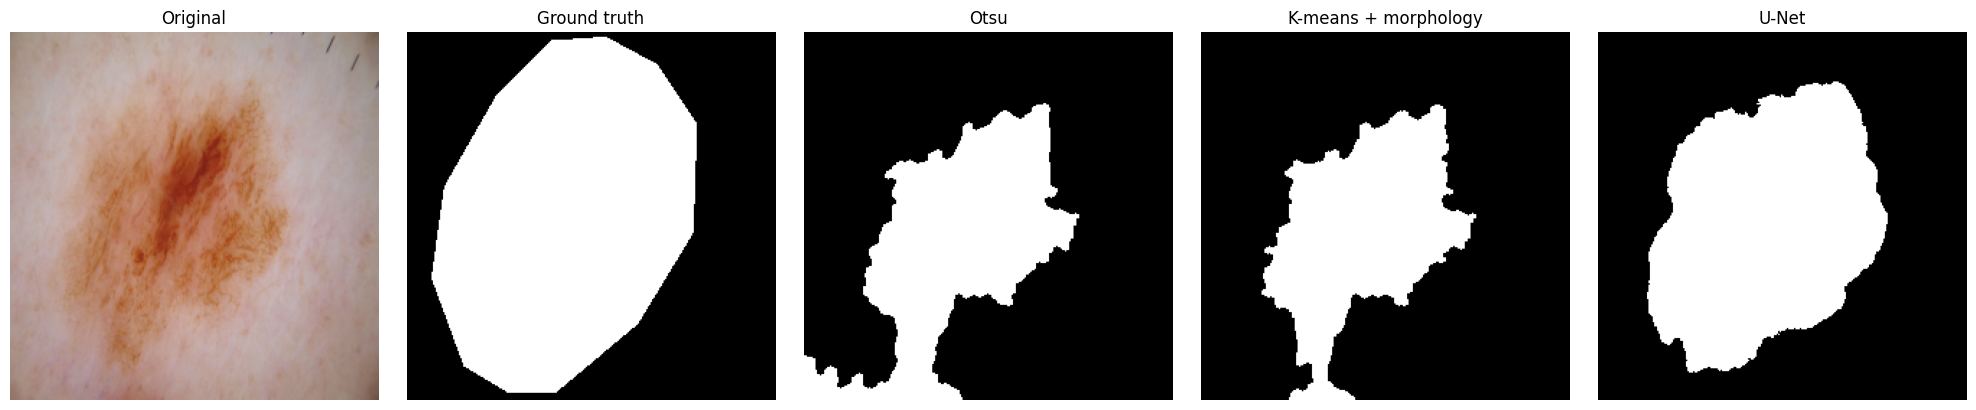

Saved: /content/skin-lesion-analyzer/results/figures/comparison.png


In [12]:
best_method = results.iloc[0]['method']
sample_idx = int(test_idx[0])
sample_image = images_uint8[sample_idx]
sample_truth = masks_uint8[sample_idx]
sample_otsu = otsu_segmentation(sample_image)
sample_kmeans = kmeans_segmentation(sample_image)
sample_unet = predict_unet(model, sample_image)

views = [sample_image, sample_truth, sample_otsu, sample_kmeans, sample_unet]
titles = ['Original', 'Ground truth', 'Otsu', 'K-means + morphology', 'U-Net']
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, title, view in zip(axes, titles, views):
    if view.ndim == 2:
        ax.imshow(view, cmap='gray', vmin=0, vmax=1)
    else:
        ax.imshow(view)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
comparison_path = FIGURES_DIR / 'comparison.png'
plt.savefig(comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', comparison_path)

In [13]:
prediction_by_method = {
    'Otsu': sample_otsu,
    'K-means + Morphology': sample_kmeans,
    'U-Net': sample_unet,
}
selected_prediction = prediction_by_method[best_method]
features = extract_abcd_features(sample_image, selected_prediction)
feature_table = pd.DataFrame({
    'feature': ['asymmetry', 'border_irregularity', 'colour_variation', 'diameter_pixels'],
    'value': [features['asymmetry'], features['border_irregularity'], features['colour_variation'], features['diameter_pixels']],
})
display(feature_table)
print('Descriptor note: diameter is reported in pixels because no physical calibration is available.')

,feature,value
0,asymmetry,0.413328
1,border_irregularity,0.398897
2,colour_variation,0.096799
3,diameter_pixels,202.000000


Descriptor note: diameter is reported in pixels because no physical calibration is available.


## Package the final outputs

The ZIP contains the trained U-Net, real benchmark CSV, comparison image, and training-history image. Download it and use the CSV and comparison figure in the presentation.

In [14]:
OUTPUT_DIR = Path('/content/skin_lesion_analyzer_outputs')
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
(OUTPUT_DIR / 'model').mkdir(parents=True)
(OUTPUT_DIR / 'results' / 'figures').mkdir(parents=True)

shutil.copy2(model_path, OUTPUT_DIR / 'model' / 'unet_skin_lesion.keras')
shutil.copy2(RESULTS_DIR / 'benchmark_results.csv', OUTPUT_DIR / 'results' / 'benchmark_results.csv')
for figure in FIGURES_DIR.glob('*.png'):
    shutil.copy2(figure, OUTPUT_DIR / 'results' / 'figures' / figure.name)

archive_base = '/content/skin_lesion_analyzer_outputs'
archive_path = shutil.make_archive(archive_base, 'zip', root_dir=OUTPUT_DIR)
print('Created:', archive_path)
files.download(archive_path)

Created: /content/skin_lesion_analyzer_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import cv2
import numpy as np
import pandas as pd

def image_quality_report(image, mask):
    image = np.asarray(image).astype(np.uint8)
    mask = (np.asarray(mask) > 0).astype(np.uint8)

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    height, width = mask.shape

    lesion_area = float(mask.mean())
    touches_border = bool(
        mask[0].any() or mask[-1].any() or
        mask[:, 0].any() or mask[:, -1].any()
    )

    laplacian_variance = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    brightness = float(gray.mean())
    contrast = float(gray.std())

    flags = []

    if laplacian_variance < 50:
        flags.append("possibly_blurred")

    if brightness < 40 or brightness > 220:
        flags.append("poor_brightness")

    if contrast < 20:
        flags.append("low_contrast")

    if lesion_area < 0.01 or lesion_area > 0.80:
        flags.append("unusual_lesion_area")

    if touches_border:
        flags.append("lesion_touches_image_border")

    return {
        "brightness": brightness,
        "contrast": contrast,
        "laplacian_variance": laplacian_variance,
        "lesion_area_fraction": lesion_area,
        "touches_border": touches_border,
        "quality_status": "review" if flags else "acceptable",
        "quality_flags": ", ".join(flags) if flags else "none",
    }


def predict_method(image, method):
    if method == "Otsu":
        return otsu_segmentation(image)
    if method == "K-means + Morphology":
        return kmeans_segmentation(image)
    if method == "U-Net":
        return predict_unet(model, image)
    raise ValueError(method)


quality_rows = []

for idx in test_idx:
    image = images_uint8[idx]
    prediction = predict_method(image, best_method)

    row = image_quality_report(image, prediction)
    row["image"] = pairs[idx][0].stem
    quality_rows.append(row)

quality_df = pd.DataFrame(quality_rows)
display(quality_df.head())

quality_df.to_csv(
    RESULTS_DIR / "image_quality_checks.csv",
    index=False
)

print("Saved:", RESULTS_DIR / "image_quality_checks.csv")

,brightness,contrast,laplacian_variance,lesion_area_fraction,touches_border,quality_status,quality_flags,image
0,156.535583,20.933169,61.384376,0.359940,False,acceptable,none,ISIC_0000436
1,136.440689,32.662708,109.137277,0.063736,False,acceptable,none,ISIC_0000079
2,172.040771,20.344378,149.507872,0.199280,False,acceptable,none,ISIC_0000458
3,181.041275,52.502359,391.528180,0.412811,True,review,lesion_touches_image_border,ISIC_0000171
4,154.624008,34.044825,1440.665006,0.227325,False,acceptable,none,ISIC_0000115


Saved: /content/skin-lesion-analyzer/results/image_quality_checks.csv


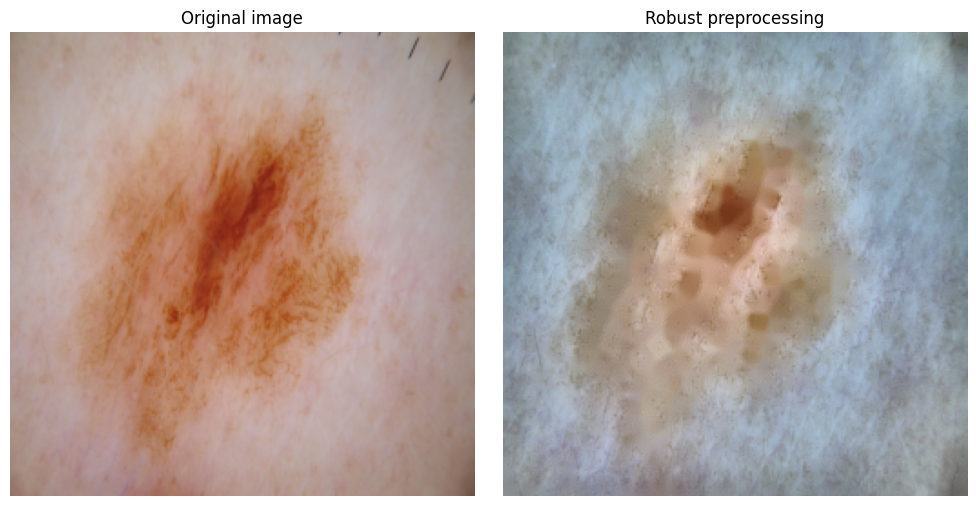

In [16]:
from analyzer.preprocessing import (
    ensure_rgb,
    apply_clahe,
    remove_hair_artifacts,
)

def gray_world_white_balance(image):
    image = ensure_rgb(image).astype(np.float32)

    channel_means = image.reshape(-1, 3).mean(axis=0)
    target_mean = channel_means.mean()
    scale = target_mean / np.maximum(channel_means, 1.0)

    balanced = image * scale
    return np.clip(balanced, 0, 255).astype(np.uint8)


def illumination_correction(image):
    image = ensure_rgb(image)

    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    lightness = lab[:, :, 0].astype(np.float32)

    background = cv2.GaussianBlur(
        lightness,
        (0, 0),
        sigmaX=25,
        sigmaY=25,
    )

    corrected = lightness / np.maximum(background, 1.0)
    corrected *= background.mean()

    lab[:, :, 0] = np.clip(corrected, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def robust_preprocess(image):
    image = gray_world_white_balance(image)
    image = illumination_correction(image)

    image, hair_mask = remove_hair_artifacts(
        image,
        kernel_size=17,
        inpaint_radius=3,
    )

    image = apply_clahe(image)
    return image


sample_image = images_uint8[int(test_idx[0])]
robust_image = robust_preprocess(sample_image)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(sample_image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(robust_image)
axes[1].set_title("Robust preprocessing")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [17]:
def evaluate_preprocessing(method, preprocessing_function):
    ious = []
    dices = []

    for idx in test_idx:
        image = preprocessing_function(images_uint8[idx])
        truth = masks_uint8[idx]

        prediction = predict_method(image, method)

        ious.append(iou_score(prediction, truth))
        dices.append(dice_score(prediction, truth))

    return summarize_scores(ious, dices)


preprocessing_ablation = pd.DataFrame([
    {
        "method": method,
        "preprocessing": preprocessing_name,
        **evaluate_preprocessing(method, preprocessing_function),
    }
    for method in ["Otsu", "K-means + Morphology"]
    for preprocessing_name, preprocessing_function in [
        ("original", lambda image: image),
        ("robust", robust_preprocess),
    ]
])

display(preprocessing_ablation)

preprocessing_ablation.to_csv(
    RESULTS_DIR / "preprocessing_ablation.csv",
    index=False
)

,method,preprocessing,n_samples,mean_iou,std_iou,median_iou,mean_dice,std_dice,median_dice
0,Otsu,original,100,0.607619,0.273324,0.662621,0.710754,0.269990,0.797076
1,Otsu,robust,100,0.367028,0.242614,0.391890,0.489194,0.273499,0.563092
2,K-means + Morphology,original,100,0.561836,0.294455,0.636821,0.663121,0.303717,0.778119
3,K-means + Morphology,robust,100,0.408671,0.249266,0.428213,0.531772,0.277830,0.599649


In [18]:
import base64
import html
from io import BytesIO

from analyzer.visualization import overlay_mask, contour_overlay


def image_data_uri(image, mode="RGB"):
    image = np.asarray(image)

    if mode == "L":
        image = (image > 0).astype(np.uint8) * 255
        pil_image = Image.fromarray(image, mode="L")
    else:
        pil_image = Image.fromarray(image.astype(np.uint8), mode="RGB")

    buffer = BytesIO()
    pil_image.save(buffer, format="PNG")

    encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")
    return f"data:image/png;base64,{encoded}"


sample_idx = int(test_idx[0])
sample_image = images_uint8[sample_idx]
sample_prediction = predict_method(sample_image, best_method)
sample_features = extract_abcd_features(sample_image, sample_prediction)
sample_quality = image_quality_report(sample_image, sample_prediction)

sample_overlay = overlay_mask(sample_image, sample_prediction)
sample_contour = contour_overlay(sample_image, sample_prediction)

feature_table = pd.DataFrame({
    "Feature": [
        "Asymmetry",
        "Border irregularity",
        "Colour variation",
        "Diameter",
    ],
    "Value": [
        f"{sample_features['asymmetry']:.4f}",
        f"{sample_features['border_irregularity']:.4f}",
        f"{sample_features['colour_variation']:.4f}",
        f"{sample_features['diameter_pixels']:.0f} pixels",
    ],
}).to_html(index=False)

metrics_table = results.to_html(
    index=False,
    float_format=lambda value: f"{value:.4f}",
)

report_html = f"""
<!doctype html>
<html>
<head>
<meta charset="utf-8">
<title>Skin Lesion Image Analysis Report</title>
<style>
body {{
    font-family: Arial, sans-serif;
    max-width: 1100px;
    margin: 30px auto;
    color: #222;
}}
.grid {{
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    gap: 16px;
}}
.card {{
    border: 1px solid #ddd;
    padding: 12px;
}}
img {{
    width: 100%;
    border: 1px solid #ccc;
}}
table {{
    border-collapse: collapse;
    margin: 15px 0;
    width: 100%;
}}
th, td {{
    border: 1px solid #ccc;
    padding: 8px;
    text-align: left;
}}
.warning {{
    background: #fff3cd;
    padding: 12px;
}}
</style>
</head>

<body>
<h1>Skin Lesion Image Analysis Report</h1>

<div class="warning">
This is an educational image-analysis report. It is not a medical diagnosis
or clinical decision-support tool.
</div>

<h2>Selected segmentation method</h2>
<p><strong>{html.escape(str(best_method))}</strong></p>

<h2>Visual result</h2>
<div class="grid">
<div class="card">
<h3>Original image</h3>
<img src="{image_data_uri(sample_image)}">
</div>

<div class="card">
<h3>Predicted mask</h3>
<img src="{image_data_uri(sample_prediction, mode='L')}">
</div>

<div class="card">
<h3>Contour overlay</h3>
<img src="{image_data_uri(sample_contour)}">
</div>
</div>

<h2>Image descriptors</h2>
{feature_table}

<h2>Image-quality checks</h2>
<table>
<tr><th>Check</th><th>Value</th></tr>
<tr><td>Brightness</td><td>{sample_quality['brightness']:.2f}</td></tr>
<tr><td>Contrast</td><td>{sample_quality['contrast']:.2f}</td></tr>
<tr><td>Blur score</td><td>{sample_quality['laplacian_variance']:.2f}</td></tr>
<tr><td>Lesion area fraction</td><td>{sample_quality['lesion_area_fraction']:.4f}</td></tr>
<tr><td>Status</td><td>{html.escape(sample_quality['quality_status'])}</td></tr>
<tr><td>Flags</td><td>{html.escape(sample_quality['quality_flags'])}</td></tr>
</table>

<h2>Method comparison</h2>
{metrics_table}

</body>
</html>
"""

report_path = Path("/content/skin_lesion_analysis_report.html")
report_path.write_text(report_html, encoding="utf-8")

print("Report created:", report_path)

from google.colab import files
files.download(str(report_path))

Report created: /content/skin_lesion_analysis_report.html


/tmp/ipykernel_631/1991570576.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pil_image = Image.fromarray(image.astype(np.uint8), mode="RGB")
/tmp/ipykernel_631/1991570576.py:13: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pil_image = Image.fromarray(image, mode="L")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

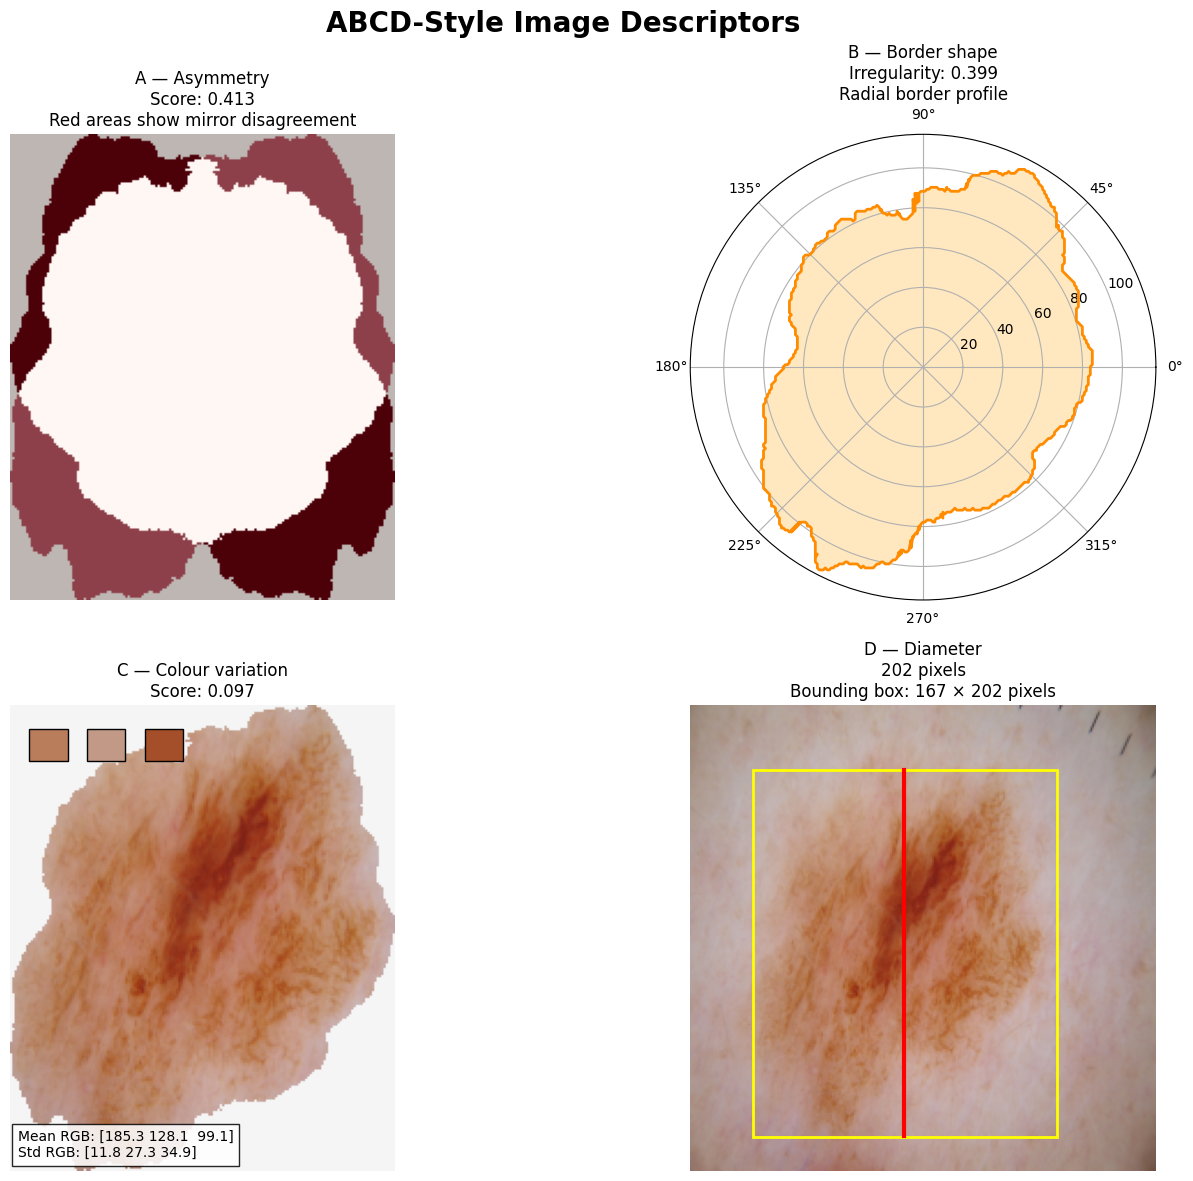

Saved: /content/skin-lesion-analyzer/results/figures/abcd_visual_dashboard.png


In [19]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from analyzer.abcd_features import extract_abcd_features
from analyzer.classical_segmentation import (
    otsu_segmentation,
    kmeans_segmentation,
)
from analyzer.unet_segmentation import predict_unet


# Select one held-out test image
sample_idx = int(test_idx[0])
sample_image = images_uint8[sample_idx]

if best_method == "Otsu":
    sample_prediction = otsu_segmentation(sample_image)
elif best_method == "K-means + Morphology":
    sample_prediction = kmeans_segmentation(sample_image)
else:
    sample_prediction = predict_unet(model, sample_image)

sample_prediction = (sample_prediction > 0).astype(np.uint8)
features = extract_abcd_features(sample_image, sample_prediction)

mask = sample_prediction
ys, xs = np.where(mask > 0)

if len(xs) == 0:
    raise ValueError("No lesion detected in the selected image.")

xmin, xmax = xs.min(), xs.max()
ymin, ymax = ys.min(), ys.max()

mask_crop = mask[ymin:ymax + 1, xmin:xmax + 1]
image_crop = sample_image[ymin:ymax + 1, xmin:xmax + 1].copy()
image_crop[mask_crop == 0] = [245, 245, 245]

# A: horizontal mirror difference
mirror = np.fliplr(mask_crop)
asymmetry_map = np.logical_xor(mask_crop, mirror)

# B: border radial profile
contours, _ = cv2.findContours(
    (mask * 255).astype(np.uint8),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE,
)

contour = max(contours, key=cv2.contourArea)
moments = cv2.moments(contour)

cx = moments["m10"] / moments["m00"]
cy = moments["m01"] / moments["m00"]

points = contour[:, 0, :].astype(float)
dx = points[:, 0] - cx
dy = points[:, 1] - cy

angles = np.arctan2(-dy, dx)
radii = np.sqrt(dx ** 2 + dy ** 2)
order = np.argsort(angles)

# D: pixel diameter
box_width = xmax - xmin + 1
box_height = ymax - ymin + 1
diameter = max(box_width, box_height)

fig = plt.figure(figsize=(16, 12))

# A
ax_a = fig.add_subplot(221)
ax_a.imshow(mask_crop, cmap="gray", vmin=0, vmax=1)
ax_a.imshow(
    asymmetry_map,
    cmap="Reds",
    alpha=0.75,
    vmin=0,
    vmax=1,
)
ax_a.set_title(
    f"A — Asymmetry\n"
    f"Score: {features['asymmetry']:.3f}\n"
    "Red areas show mirror disagreement"
)
ax_a.axis("off")

# B
ax_b = fig.add_subplot(222, projection="polar")
ax_b.plot(angles[order], radii[order], color="darkorange", linewidth=2)
ax_b.fill(angles[order], radii[order], color="orange", alpha=0.25)
ax_b.set_title(
    f"B — Border shape\n"
    f"Irregularity: {features['border_irregularity']:.3f}\n"
    "Radial border profile",
    pad=25,
)

# C
ax_c = fig.add_subplot(223)
ax_c.imshow(image_crop)
ax_c.set_title(
    f"C — Colour variation\n"
    f"Score: {features['colour_variation']:.3f}"
)
ax_c.axis("off")

mean_rgb = np.array(features["mean_rgb"])
std_rgb = np.array(features["std_rgb"])

ax_c.text(
    0.02,
    0.03,
    f"Mean RGB: {mean_rgb.round(1)}\n"
    f"Std RGB: {std_rgb.round(1)}",
    transform=ax_c.transAxes,
    color="black",
    bbox=dict(facecolor="white", alpha=0.85),
)

# Dominant colour swatches
for i, colour in enumerate(features["dominant_colours"]):
    colour = np.array(colour) / 255.0
    ax_c.add_patch(
        Rectangle(
            (0.05 + i * 0.15, 0.88),
            0.10,
            0.07,
            transform=ax_c.transAxes,
            facecolor=colour,
            edgecolor="black",
        )
    )

# D
ax_d = fig.add_subplot(224)
ax_d.imshow(sample_image)

ax_d.add_patch(
    Rectangle(
        (xmin, ymin),
        box_width,
        box_height,
        fill=False,
        edgecolor="yellow",
        linewidth=2,
    )
)

# Diameter line
if box_width >= box_height:
    y_mid = (ymin + ymax) / 2
    ax_d.plot(
        [xmin, xmax],
        [y_mid, y_mid],
        color="red",
        linewidth=3,
    )
else:
    x_mid = (xmin + xmax) / 2
    ax_d.plot(
        [x_mid, x_mid],
        [ymin, ymax],
        color="red",
        linewidth=3,
    )

ax_d.set_title(
    f"D — Diameter\n"
    f"{diameter:.0f} pixels\n"
    f"Bounding box: {box_width} × {box_height} pixels"
)
ax_d.axis("off")

fig.suptitle(
    "ABCD-Style Image Descriptors",
    fontsize=20,
    fontweight="bold",
)

plt.tight_layout()

dashboard_path = FIGURES_DIR / "abcd_visual_dashboard.png"
plt.savefig(dashboard_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", dashboard_path)

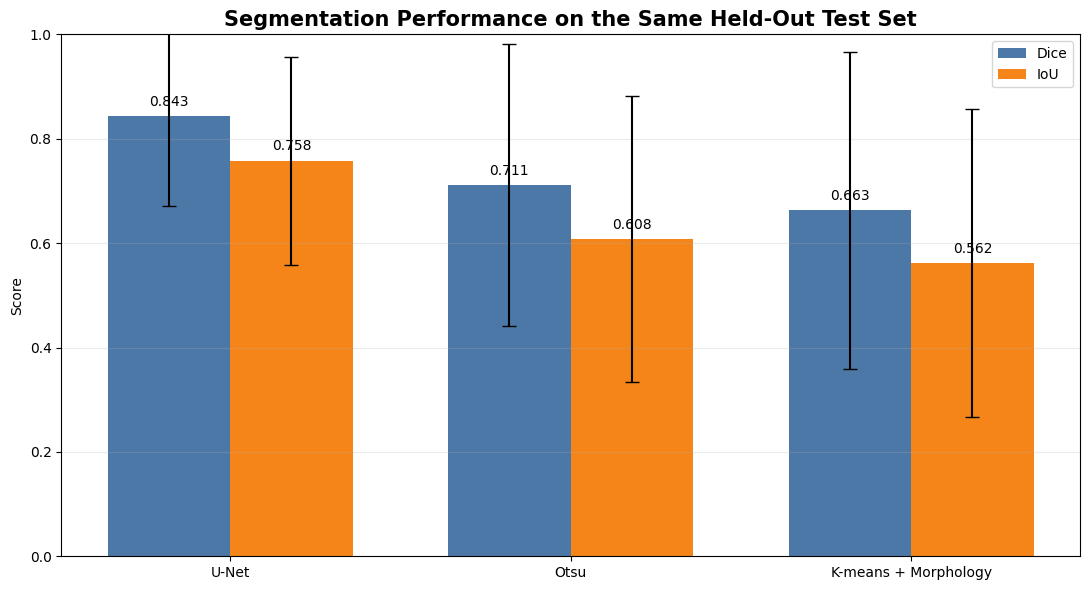

Saved: /content/skin-lesion-analyzer/results/figures/method_comparison_dice_iou.png


In [20]:
import numpy as np
import matplotlib.pyplot as plt

methods = results["method"].tolist()
x = np.arange(len(methods))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

dice_bars = ax.bar(
    x - width / 2,
    results["mean_dice"],
    width,
    yerr=results["std_dice"],
    capsize=5,
    label="Dice",
    color="#4C78A8",
)

iou_bars = ax.bar(
    x + width / 2,
    results["mean_iou"],
    width,
    yerr=results["std_iou"],
    capsize=5,
    label="IoU",
    color="#F58518",
)

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title(
    "Segmentation Performance on the Same Held-Out Test Set",
    fontsize=15,
    fontweight="bold",
)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for bars in [dice_bars, iou_bars]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            f"{height:.3f}",
            ha="center",
            fontsize=10,
        )

plt.tight_layout()

method_plot_path = FIGURES_DIR / "method_comparison_dice_iou.png"
plt.savefig(method_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", method_plot_path)

In [21]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def predict_for_method(image, method):
    if method == "Otsu":
        return otsu_segmentation(image)

    if method == "K-means + Morphology":
        return kmeans_segmentation(image)

    if method == "U-Net":
        return predict_unet(model, image)

    raise ValueError(method)


def change_brightness(image, factor):
    return cv2.convertScaleAbs(
        image,
        alpha=float(factor),
        beta=0,
    )


def add_gaussian_blur(image, sigma):
    if sigma == 0:
        return image.copy()

    return cv2.GaussianBlur(
        image,
        ksize=(0, 0),
        sigmaX=float(sigma),
    )


def evaluate_condition(method, condition, level, transform_function):
    dice_values = []
    iou_values = []

    for idx in test_idx:
        original = images_uint8[idx]
        truth = masks_uint8[idx]

        transformed = transform_function(original)
        prediction = predict_for_method(transformed, method)

        dice_values.append(dice_score(prediction, truth))
        iou_values.append(iou_score(prediction, truth))

    return {
        "method": method,
        "condition": condition,
        "level": level,
        "mean_dice": np.mean(dice_values),
        "std_dice": np.std(dice_values),
        "mean_iou": np.mean(iou_values),
        "std_iou": np.std(iou_values),
        "n_samples": len(dice_values),
    }


methods = [
    "Otsu",
    "K-means + Morphology",
    "U-Net",
]

rows = []

brightness_levels = [0.70, 0.85, 1.00, 1.15, 1.30]
blur_levels = [0, 1, 2, 4, 6]

for method in methods:
    for factor in brightness_levels:
        rows.append(
            evaluate_condition(
                method=method,
                condition="brightness",
                level=factor,
                transform_function=lambda image, factor=factor:
                    change_brightness(image, factor),
            )
        )

    for sigma in blur_levels:
        rows.append(
            evaluate_condition(
                method=method,
                condition="gaussian_blur",
                level=sigma,
                transform_function=lambda image, sigma=sigma:
                    add_gaussian_blur(image, sigma),
            )
        )

robustness_df = pd.DataFrame(rows)

display(robustness_df)

robustness_path = RESULTS_DIR / "robustness_results.csv"
robustness_df.to_csv(robustness_path, index=False)

print("Saved:", robustness_path)

,method,condition,level,mean_dice,std_dice,mean_iou,std_iou,n_samples
0,Otsu,brightness,0.70,0.711491,0.269645,0.608375,0.272916,100
1,Otsu,brightness,0.85,0.711066,0.269941,0.607977,0.273227,100
2,Otsu,brightness,1.00,0.710754,0.269990,0.607619,0.273324,100
3,Otsu,brightness,1.15,0.706395,0.268348,0.601357,0.270936,100
4,Otsu,brightness,1.30,0.699078,0.267149,0.591000,0.265618,100
5,Otsu,gaussian_blur,0.00,0.710754,0.269990,0.607619,0.273324,100
6,Otsu,gaussian_blur,1.00,0.708281,0.270477,0.604898,0.274647,100
7,Otsu,gaussian_blur,2.00,0.709751,0.270643,0.606800,0.274827,100
8,Otsu,gaussian_blur,4.00,0.711527,0.277608,0.611574,0.279775,100
9,Otsu,gaussian_blur,6.00,0.706764,0.289452,0.609975,0.287654,100


Saved: /content/skin-lesion-analyzer/results/robustness_results.csv


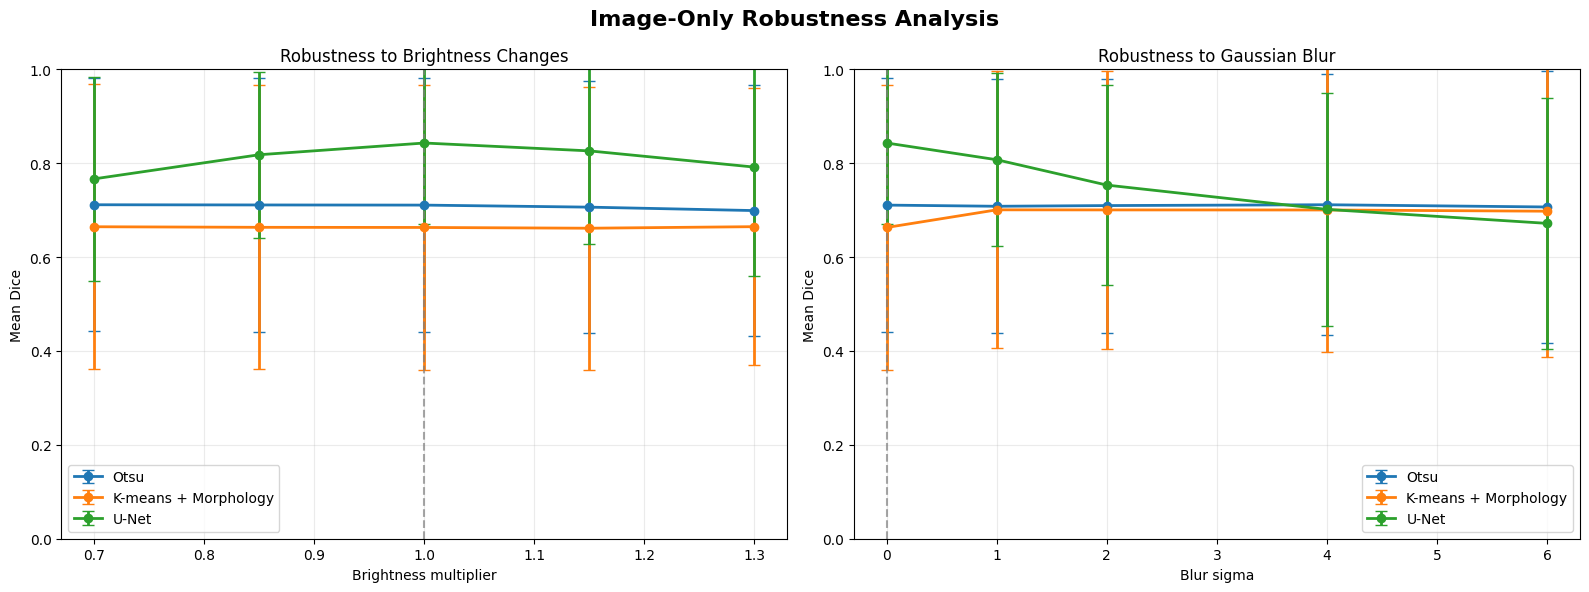

Saved: /content/skin-lesion-analyzer/results/figures/robustness_dice_plot.png


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Brightness robustness
brightness_df = robustness_df[
    robustness_df["condition"] == "brightness"
]

for method in methods:
    subset = brightness_df[
        brightness_df["method"] == method
    ].sort_values("level")

    axes[0].errorbar(
        subset["level"],
        subset["mean_dice"],
        yerr=subset["std_dice"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method,
    )

axes[0].axvline(
    1.0,
    color="gray",
    linestyle="--",
    alpha=0.7,
)

axes[0].set_title("Robustness to Brightness Changes")
axes[0].set_xlabel("Brightness multiplier")
axes[0].set_ylabel("Mean Dice")
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.25)
axes[0].legend()


# Blur robustness
blur_df = robustness_df[
    robustness_df["condition"] == "gaussian_blur"
]

for method in methods:
    subset = blur_df[
        blur_df["method"] == method
    ].sort_values("level")

    axes[1].errorbar(
        subset["level"],
        subset["mean_dice"],
        yerr=subset["std_dice"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method,
    )

axes[1].axvline(
    0,
    color="gray",
    linestyle="--",
    alpha=0.7,
)

axes[1].set_title("Robustness to Gaussian Blur")
axes[1].set_xlabel("Blur sigma")
axes[1].set_ylabel("Mean Dice")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.suptitle(
    "Image-Only Robustness Analysis",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout()

robustness_plot_path = FIGURES_DIR / "robustness_dice_plot.png"
plt.savefig(
    robustness_plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", robustness_plot_path)

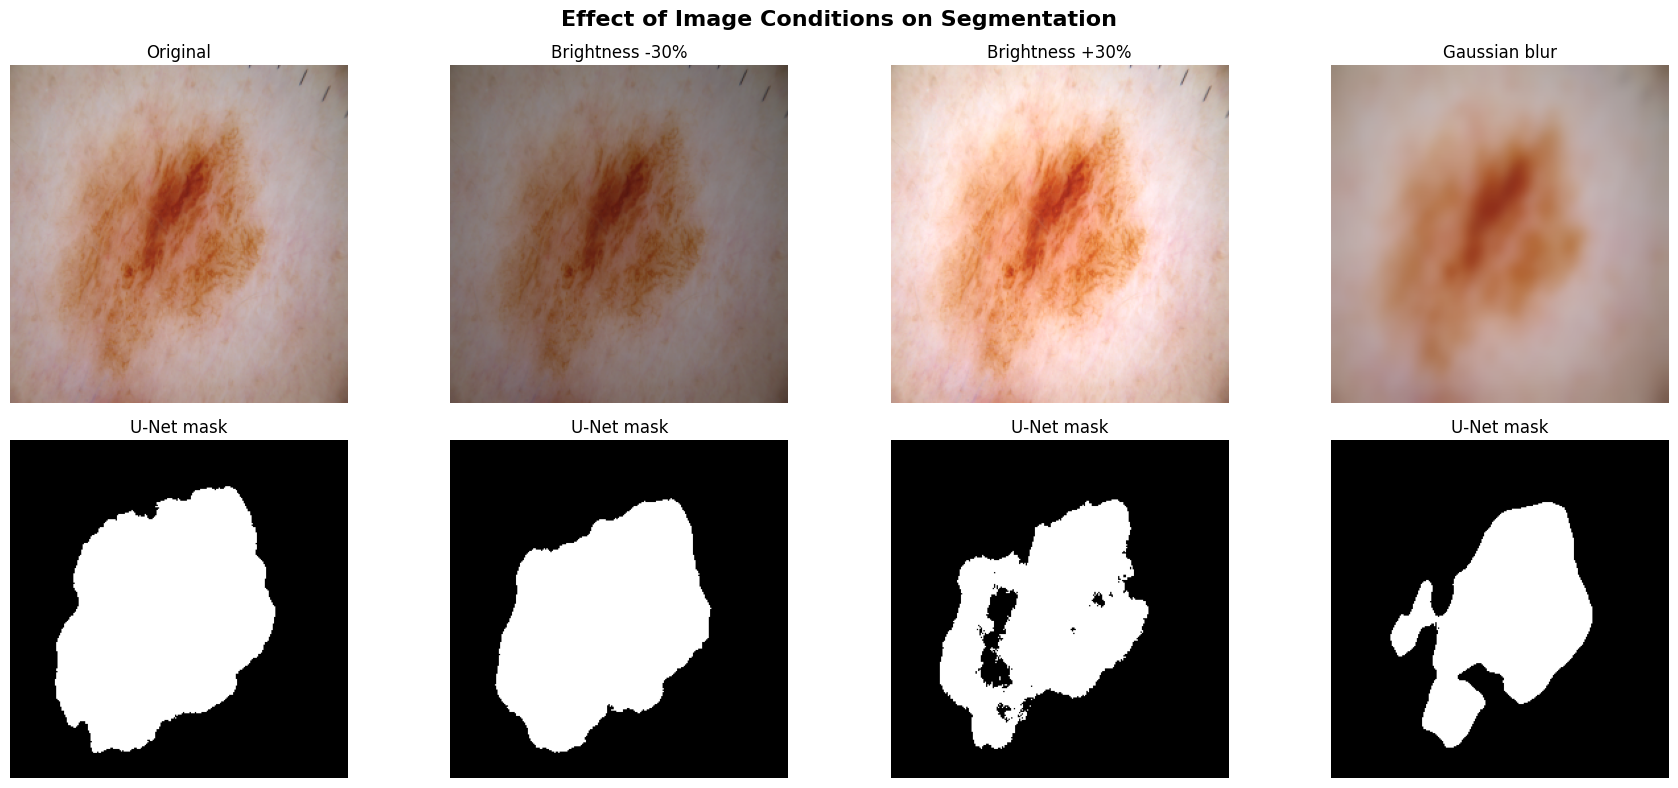

Saved: /content/skin-lesion-analyzer/results/figures/robustness_visual_examples.png


In [23]:
sample_idx = int(test_idx[0])
original = images_uint8[sample_idx]

examples = [
    ("Original", original),
    ("Brightness -30%", change_brightness(original, 0.70)),
    ("Brightness +30%", change_brightness(original, 1.30)),
    ("Gaussian blur", add_gaussian_blur(original, 4)),
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for column, (title, image) in enumerate(examples):
    prediction = predict_for_method(image, best_method)

    axes[0, column].imshow(image)
    axes[0, column].set_title(title)
    axes[0, column].axis("off")

    axes[1, column].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[1, column].set_title(f"{best_method} mask")
    axes[1, column].axis("off")

plt.suptitle(
    "Effect of Image Conditions on Segmentation",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout()

example_path = FIGURES_DIR / "robustness_visual_examples.png"
plt.savefig(example_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", example_path)

In [26]:
from analyzer.unet_segmentation import (
    dice_bce_loss,
    dice_metric,
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=dice_bce_loss,
    metrics=[
        dice_metric,
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou",
        ),
    ],
)

print("ResNet50-U-Net compiled successfully.")

ResNet50-U-Net compiled successfully.


In [27]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def decoder_block(x, skip, filters):
    x = tf.keras.layers.Conv2DTranspose(
        filters,
        kernel_size=3,
        strides=2,
        padding="same",
    )(x)

    if skip is not None:
        x = tf.keras.layers.Concatenate()([x, skip])

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)

    return x


def build_resnet50_unet(input_shape=(256, 256, 3)):
    inputs = tf.keras.layers.Input(shape=input_shape)

    # Convert [0, 1] input into the format expected by ImageNet ResNet50
    resnet_input = tf.keras.layers.Lambda(
        lambda image: tf.keras.applications.resnet50.preprocess_input(
            image * 255.0
        ),
        name="resnet_preprocessing",
    )(inputs)

    encoder = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=resnet_input,
    )

    # ResNet feature maps
    skip1 = encoder.get_layer("conv1_relu").output
    skip2 = encoder.get_layer("conv2_block3_out").output
    skip3 = encoder.get_layer("conv3_block4_out").output
    skip4 = encoder.get_layer("conv4_block6_out").output
    bottleneck = encoder.get_layer("conv5_block3_out").output

    # Freeze pretrained encoder
    for layer in encoder.layers:
        layer.trainable = False

    x = decoder_block(bottleneck, skip4, 512)
    x = decoder_block(x, skip3, 256)
    x = decoder_block(x, skip2, 128)
    x = decoder_block(x, skip1, 64)
    x = decoder_block(x, None, 32)

    outputs = tf.keras.layers.Conv2D(
        1,
        kernel_size=1,
        activation="sigmoid",
        name="lesion_mask",
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name="resnet50_unet_skin_lesion",
    )


resnet_model = build_resnet50_unet((*TARGET_SIZE, 3))

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_bce_loss,
    metrics=[
        dice_metric,
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou",
        ),
    ],
)

resnet_model.summary()

Model: "resnet50_unet_skin_lesion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet_preprocessi… │ (None, 256, 256,  │          0 │ input_layer_2[0]… │
│ (Lambda)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 262, 262,  │          0 │ resnet_preproces… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 128, 128,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 128, 128,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 130, 130,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 64, 64,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 64, 64,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 64, 64,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 64, 64,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_0_c

 Total params: 47,117,889 (179.74 MB)

 Trainable params: 23,526,209 (89.75 MB)

 Non-trainable params: 23,591,680 (90.00 MB)

ResNet50-U-Net compiled successfully.
Epoch 1/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 80s 193ms/step - dice_metric: 0.7332 - iou: 0.7208 - loss: 0.5470 - val_dice_metric: 0.7743 - val_iou: 0.8193 - val_loss: 0.4951 - learning_rate: 1.0000e-04
Epoch 2/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 25s 155ms/step - dice_metric: 0.8243 - iou: 0.8258 - loss: 0.3575 - val_dice_metric: 0.8497 - val_iou: 0.8437 - val_loss: 0.3316 - learning_rate: 1.0000e-04
Epoch 3/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 18s 112ms/step - dice_metric: 0.8582 - iou: 0.8661 - loss: 0.2862 - val_dice_metric: 0.8484 - val_iou: 0.8312 - val_loss: 0.3681 - learning_rate: 1.0000e-04
Epoch 4/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 17s 106ms/step - dice_metric: 0.8801 - iou: 0.8886 - loss: 0.2390 - val_dice_metric: 0.8556 - val_iou: 0.8128 - val_loss: 0.4356 - learning_rate: 1.0000e-04
Epoch 5/15
160/160 ━━━━━━━━━━━━━━━━━━━━ 22s 140ms/step - dice_metric: 0.8946 - iou: 0.9043 - loss: 0.2068 - val_dice_metric: 0.8639 - val_iou: 0.8486 - val_loss: 0.3025 - lea

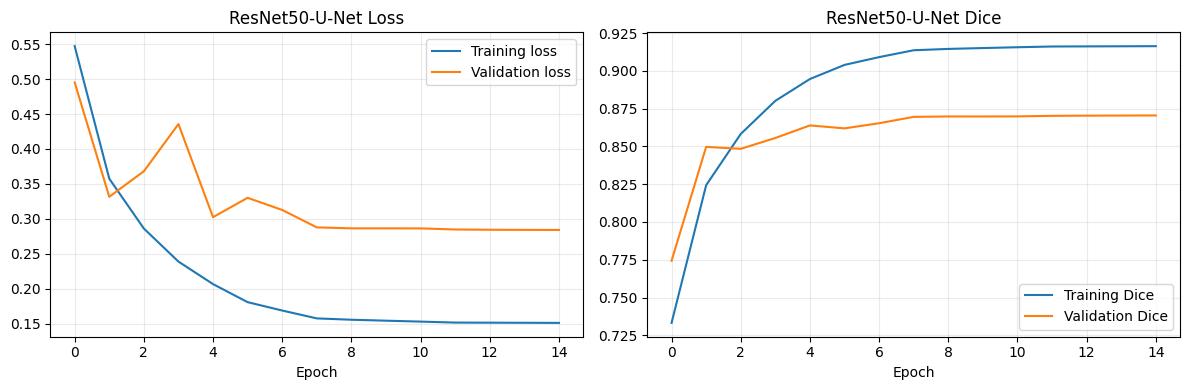

,dataset,source,method,n_samples,mean_iou,std_iou,median_iou,mean_dice,std_dice,median_dice
0,ISIC2018_Task1,executed Colab benchmark on held-out test split,ResNet50-U-Net,100,0.828692,0.150887,0.880040,0.896766,0.118302,0.936191
1,ISIC2018_Task1,executed Colab benchmark on held-out test split,U-Net,100,0.757573,0.198944,0.815040,0.843036,0.171547,0.898095
2,ISIC2018_Task1,executed Colab benchmark on held-out test split,Otsu,100,0.607619,0.273324,0.662621,0.710754,0.269990,0.797076
3,ISIC2018_Task1,executed Colab benchmark on held-out test split,K-means + Morphology,100,0.561836,0.294455,0.636821,0.663121,0.303717,0.778119


Results saved to: /content/skin-lesion-analyzer/results/benchmark_results_with_resnet.csv


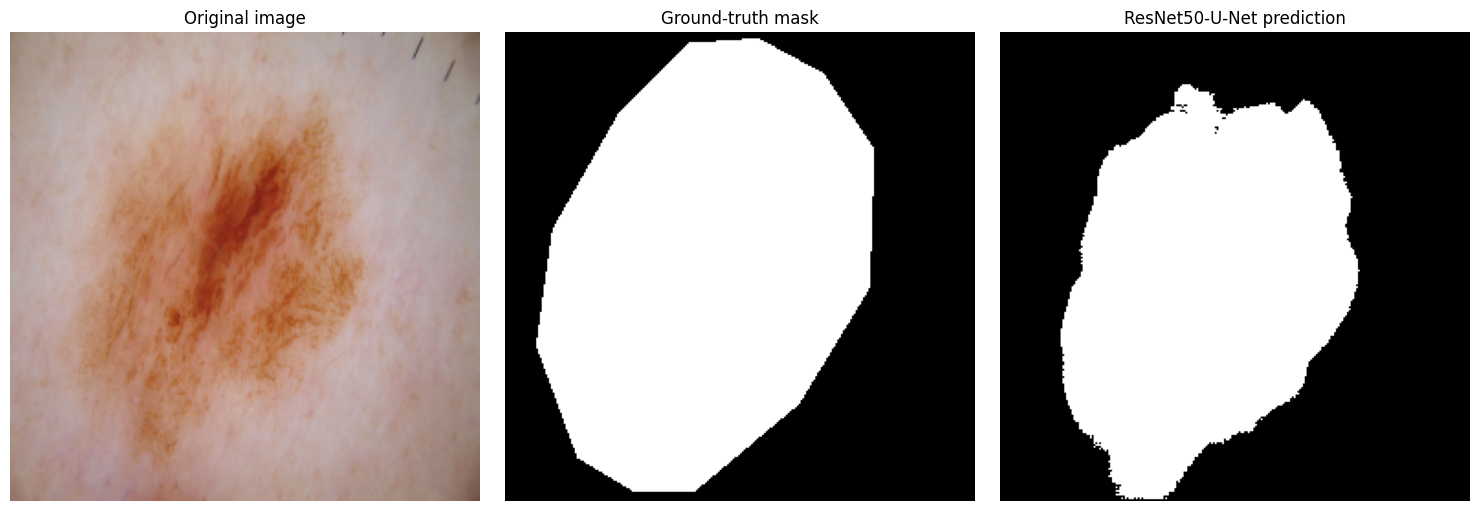

Prediction figure saved to: /content/skin-lesion-analyzer/results/figures/resnet50_unet_prediction.png


In [28]:
import gc
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from analyzer.metrics import (
    dice_score,
    iou_score,
    summarize_scores,
)

from analyzer.unet_segmentation import (
    dice_bce_loss,
    dice_metric,
)


# ---------------------------------------------------------
# 1. Build ResNet50-U-Net with ImageNet preprocessing
# ---------------------------------------------------------

def decoder_block(x, skip, filters):
    x = tf.keras.layers.Conv2DTranspose(
        filters,
        kernel_size=3,
        strides=2,
        padding="same",
    )(x)

    if skip is not None:
        x = tf.keras.layers.Concatenate()([x, skip])

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Conv2D(
        filters,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)

    return x


def build_resnet50_unet(input_shape=(256, 256, 3)):
    inputs = tf.keras.layers.Input(shape=input_shape)

    # images are currently stored in the range [0, 1]
    # ResNet preprocessing converts them to ImageNet format
    resnet_input = tf.keras.layers.Lambda(
        lambda x: tf.keras.applications.resnet50.preprocess_input(
            x * 255.0
        ),
        name="resnet50_preprocessing",
    )(inputs)

    encoder = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=resnet_input,
    )

    skip1 = encoder.get_layer("conv1_relu").output
    skip2 = encoder.get_layer("conv2_block3_out").output
    skip3 = encoder.get_layer("conv3_block4_out").output
    skip4 = encoder.get_layer("conv4_block6_out").output
    bottleneck = encoder.get_layer("conv5_block3_out").output

    # Freeze pretrained ResNet encoder
    for layer in encoder.layers:
        layer.trainable = False

    x = decoder_block(bottleneck, skip4, 512)
    x = decoder_block(x, skip3, 256)
    x = decoder_block(x, skip2, 128)
    x = decoder_block(x, skip1, 64)
    x = decoder_block(x, None, 32)

    outputs = tf.keras.layers.Conv2D(
        1,
        kernel_size=1,
        activation="sigmoid",
        name="lesion_mask",
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name="resnet50_unet_skin_lesion",
    )


# ---------------------------------------------------------
# 2. Create and compile model
# ---------------------------------------------------------

resnet_model = build_resnet50_unet(
    (*TARGET_SIZE, 3)
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=dice_bce_loss,
    metrics=[
        dice_metric,
        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou",
        ),
    ],
)

print("ResNet50-U-Net compiled successfully.")


# ---------------------------------------------------------
# 3. Train model
# ---------------------------------------------------------

MODEL_DIR = Path(PROJECT_ROOT) / "model"
RESULTS_DIR = Path(PROJECT_ROOT) / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

resnet_model_path = (
    MODEL_DIR / "resnet50_unet_skin_lesion.keras"
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        patience=4,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        patience=2,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        resnet_model_path,
        save_best_only=True,
    ),
]

resnet_history = resnet_model.fit(
    images[train_idx],
    masks[train_idx],
    validation_data=(
        images[val_idx],
        masks[val_idx],
    ),
    epochs=15,
    batch_size=2,
    callbacks=callbacks,
)

print("Model saved to:", resnet_model_path)


# ---------------------------------------------------------
# 4. Plot training history
# ---------------------------------------------------------

history_df = pd.DataFrame(
    resnet_history.history
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

axes[0].plot(
    history_df["loss"],
    label="Training loss",
)

axes[0].plot(
    history_df["val_loss"],
    label="Validation loss",
)

axes[0].set_title("ResNet50-U-Net Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    history_df["dice_metric"],
    label="Training Dice",
)

axes[1].plot(
    history_df["val_dice_metric"],
    label="Validation Dice",
)

axes[1].set_title("ResNet50-U-Net Dice")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()

history_path = (
    FIGURES_DIR / "resnet50_unet_training_history.png"
)

plt.savefig(
    history_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ---------------------------------------------------------
# 5. Evaluate on the same held-out test set
# ---------------------------------------------------------

resnet_ious = []
resnet_dices = []

for idx in test_idx:
    prediction = (
        resnet_model.predict(
            images[idx:idx + 1],
            verbose=0,
        )[0, ..., 0] >= 0.5
    ).astype(np.uint8)

    truth = masks_uint8[idx]

    resnet_ious.append(
        iou_score(prediction, truth)
    )

    resnet_dices.append(
        dice_score(prediction, truth)
    )

resnet_summary = summarize_scores(
    resnet_ious,
    resnet_dices,
)

resnet_row = pd.DataFrame([
    {
        "dataset": "ISIC2018_Task1",
        "source": (
            "executed Colab benchmark on "
            "held-out test split"
        ),
        "method": "ResNet50-U-Net",
        **resnet_summary,
    }
])

if "results" in globals():
    results_with_resnet = pd.concat(
        [results, resnet_row],
        ignore_index=True,
    )
else:
    results_with_resnet = resnet_row

results_with_resnet = (
    results_with_resnet
    .sort_values(
        ["mean_dice", "mean_iou"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(results_with_resnet)

resnet_results_path = (
    RESULTS_DIR / "benchmark_results_with_resnet.csv"
)

results_with_resnet.to_csv(
    resnet_results_path,
    index=False,
)

print("Results saved to:", resnet_results_path)


# ---------------------------------------------------------
# 6. Show one ResNet segmentation result
# ---------------------------------------------------------

sample_idx = int(test_idx[0])
sample_image = images_uint8[sample_idx]

sample_prediction = (
    resnet_model.predict(
        images[sample_idx:sample_idx + 1],
        verbose=0,
    )[0, ..., 0] >= 0.5
).astype(np.uint8)

sample_truth = masks_uint8[sample_idx]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
)

axes[0].imshow(sample_image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(sample_truth, cmap="gray")
axes[1].set_title("Ground-truth mask")
axes[1].axis("off")

axes[2].imshow(sample_prediction, cmap="gray")
axes[2].set_title("ResNet50-U-Net prediction")
axes[2].axis("off")

plt.tight_layout()

prediction_path = (
    FIGURES_DIR / "resnet50_unet_prediction.png"
)

plt.savefig(
    prediction_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Prediction figure saved to:", prediction_path)